# 06 — Ridge Stacking | PharmaDemand

**Objetivo:** combinar as previsões **LightGBM + XGBoost + SARIMAX + AutoTheta** por meio de um metamodelo `Ridge`, seguindo o padrão do notebook `05_lightgbm.ipynb` e da classe `LightGBMRegressorAnomaly`.

- **Entrada do treino:** previsões *out-of-fold* (OOF) de cada modelo-base, **nunca predições in-sample**.
- **Entrada do teste:** previsões dos modelos-base sobre um **holdout temporal realmente intocado**, produzidas por modelos treinados somente com dados anteriores ao período de teste.
- **Saída:** Ridge treinado por horizonte (`D+7` e `D+15`), métricas, coeficientes, artefatos `.joblib`/`.json` e tabela de previsões.
- **Data:** a coluna `date` deve representar a **origem da previsão**, não a data futura do alvo. `quantity` é o alvo correspondente ao horizonte.

> **Não é suficiente** usar `model.predict(df_train_lgbm)` dos modelos-base treinados em todo o treino: isso cria *target leakage* no stacking. Os arquivos de OOF precisam vir de backtests com treino anterior à validação e com exclusão dos rótulos que ainda não estariam disponíveis na origem. O notebook valida o formato, mas não consegue provar a procedência das previsões.

## 1. Imports e diretórios

Mantenha `RidgeStackingRegressor.py` em `src/models/`, como as outras classes do projeto.

In [10]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
for candidate in [ROOT, ROOT.parent, ROOT.parent.parent]:
    if (candidate / "src").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Abra o notebook dentro do projeto PharmaDemand (pasta com src/).")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config.config import MODELS_BASELINE
from src.repository.parquet_repository import ParquetRepository
from src.models.RidgeStackingRegressor import RidgeStackingRegressor

repo = ParquetRepository(base_path=ROOT / "data")
STACKING_DIR = ROOT / "data" / "stacking"
STACKING_DIR.mkdir(parents=True, exist_ok=True)
MODELS_STACKING = Path(MODELS_BASELINE) / "stacking"
MODELS_STACKING.mkdir(parents=True, exist_ok=True)
print("Raiz:", ROOT)
print("Previsoes OOF e holdout:", STACKING_DIR)
print("Modelos Ridge:", MODELS_STACKING)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Raiz: D:\PROJETOS\git_repo\PharmaDemand-ml
Previsoes OOF e holdout: D:\PROJETOS\git_repo\PharmaDemand-ml\data\stacking
Modelos Ridge: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\stacking


## 2. Configuração dos modelos-base e contratos de entrada

O notebook aceita **duas maneiras de entrada**:

**A. Consolidado (mais fácil):**

- `data/stacking/stack_oof_train.parquet`
- `data/stacking/stack_holdout_test.parquet`

Ambos com as colunas `date`, `category`, `horizon_days`, `quantity`, `pred_lightgbm`, `pred_xgboost`, `pred_sarimax`, `pred_autotheta`.

**B. Um arquivo por modelo e por tipo de previsão:**

- `data/stacking/oof_lightgbm.parquet` e `holdout_lightgbm.parquet`
- `data/stacking/oof_xgboost.parquet` e `holdout_xgboost.parquet`
- `data/stacking/oof_sarimax.parquet` e `holdout_sarimax.parquet`
- `data/stacking/oof_autotheta.parquet` e `holdout_autotheta.parquet`

Cada arquivo individual contém `date`, `category`, `horizon_days`, `quantity` e `prediction` (ou `pred_<modelo>`). A função abaixo associa as previsões pela chave e rejeita linhas com alvos divergentes, ausências ou chaves duplicadas.

`IS_GENUINE_OOF = True` deve ser definido **somente depois de conferir** que cada previsão de treino foi gerada em um fold futuro ao seu respectivo treino. É uma verificação manual de procedência; mudar esse parâmetro não transforma previsões in-sample em OOF.

In [11]:
target_col = "quantity"
KEY_COLS = ["date", "category", "horizon_days"]
#MODEL_NAMES = ["lightgbm", "xgboost", "sarimax", "autotheta"]
MODEL_NAMES = ["lightgbm", "xgboost", "sarimax"]
PRED_COLS = [f"pred_{name}" for name in MODEL_NAMES]
HORIZONS = [7, 15]
CATEGORY_FILTER = "N02BE"  # Ex.: "N02BE". None = treinar sobre todas as categorias ATC.
IS_GENUINE_OOF = True  # ALTERAR para True SOMENTE apos validar a origem OOF dos arquivos

print("Features do Ridge:", PRED_COLS)
print("Horizon(s):", HORIZONS)

Features do Ridge: ['pred_lightgbm', 'pred_xgboost', 'pred_sarimax']
Horizon(s): [7, 15]


In [12]:
def _standardize_one_model(frame: pd.DataFrame, name: str) -> pd.DataFrame:
    pred_col = f"pred_{name}"
    frame = frame.copy()
    if "prediction" in frame.columns and pred_col not in frame.columns:
        frame = frame.rename(columns={"prediction": pred_col})
    required = KEY_COLS + [target_col, pred_col]
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f"{name}: colunas ausentes {missing}")
    frame = frame[required].copy()
    frame["date"] = pd.to_datetime(frame["date"], errors="raise")
    if frame.duplicated(KEY_COLS).any():
        raise ValueError(f"{name}: chaves duplicadas em {KEY_COLS}. Inclua um identificador de origem se necessario.")
    return frame


def _merge_individual_predictions(kind: str) -> pd.DataFrame:
    frames = []
    for name in MODEL_NAMES:
        path = STACKING_DIR / f"{kind}_{name}.parquet"
        if not path.exists():
            raise FileNotFoundError(f"Arquivo esperado: {path}")
        frames.append(_standardize_one_model(pd.read_parquet(path), name))

    result = frames[0]
    for name, incoming in zip(MODEL_NAMES[1:], frames[1:]):
        result = result.merge(incoming, on=KEY_COLS, how="outer", validate="one_to_one",
                              suffixes=("", "__other"), indicator=True)
        if not (result["_merge"] == "both").all():
            raise ValueError(f"Datas/categorias/horizontes nao coincidem entre modelos: {name}.")
        if not np.allclose(result[target_col].to_numpy(dtype=float),
                           result[f"{target_col}__other"].to_numpy(dtype=float),
                           rtol=0, atol=1e-8):
            raise ValueError(f"Os valores reais 'quantity' divergem entre os modelos: {name}.")
        result = result.drop(columns=["_merge", f"{target_col}__other"])
    return result.sort_values(KEY_COLS).reset_index(drop=True)


def load_stacking_dataset(kind: str) -> pd.DataFrame:
    consolidated = STACKING_DIR / ("stack_oof_train.parquet" if kind == "oof" else "stack_holdout_test.parquet")
    if consolidated.exists():
        frame = pd.read_parquet(consolidated)
        print("Carregado consolidado:", consolidated)
    else:
        print("Consolidado ausente; juntando arquivos individuais para", kind)
        frame = _merge_individual_predictions(kind)
        frame.to_parquet(consolidated, index=False)
        print("Consolidado criado:", consolidated)
    required = KEY_COLS + [target_col] + PRED_COLS
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f"Faltam colunas no arquivo {consolidated}: {missing}")
    frame = frame[required].copy()
    frame["date"] = pd.to_datetime(frame["date"], errors="raise")
    if frame.duplicated(KEY_COLS).any():
        raise ValueError(f"Chaves duplicadas em {consolidated}. Revise KEY_COLS.")
    for col in PRED_COLS + [target_col]:
        frame[col] = pd.to_numeric(frame[col], errors="raise")
        if not np.isfinite(frame[col]).all():
            raise ValueError(f"{col}: NaN ou infinito encontrado em {consolidated}")
    return frame.sort_values(KEY_COLS).reset_index(drop=True)

## 3. Carregar previsões OOF e holdout

Diferentemente do notebook LightGBM, **não carregamos `features/anomaly_predictions.parquet` como entrada direta do Ridge**. As quatro colunas `pred_*` são suas features. O holdout não pode ter sido usado para GridSearchCV de nenhum modelo-base.

In [13]:
df_oof_train = load_stacking_dataset("oof")
df_holdout_test = load_stacking_dataset("holdout")

if CATEGORY_FILTER is not None:
    df_oof_train = df_oof_train.loc[df_oof_train["category"] == CATEGORY_FILTER].copy()
    df_holdout_test = df_holdout_test.loc[df_holdout_test["category"] == CATEGORY_FILTER].copy()

if df_oof_train.empty or df_holdout_test.empty:
    raise ValueError("O filtro de categoria ou os arquivos deixaram treino/teste vazios.")

print("Treino (OOF):", df_oof_train.shape)
print("Teste (holdout):", df_holdout_test.shape)
print("Categorias:", sorted(df_oof_train["category"].unique()))
print("Treino:", df_oof_train["date"].min(), "ate", df_oof_train["date"].max())
print("Teste:", df_holdout_test["date"].min(), "ate", df_holdout_test["date"].max())
print("Horizontes train/test:", sorted(df_oof_train["horizon_days"].unique()),
      sorted(df_holdout_test["horizon_days"].unique()))

display(df_oof_train.head(5))

Carregado consolidado: D:\PROJETOS\git_repo\PharmaDemand-ml\data\stacking\stack_oof_train.parquet
Carregado consolidado: D:\PROJETOS\git_repo\PharmaDemand-ml\data\stacking\stack_holdout_test.parquet
Treino (OOF): (396, 7)
Teste (holdout): (52, 7)
Categorias: ['N02BE']
Treino: 2015-06-23 00:00:00 ate 2019-04-02 00:00:00
Teste: 2019-04-16 00:00:00 ate 2019-10-08 00:00:00
Horizontes train/test: [np.int64(7), np.int64(15)] [np.int64(7), np.int64(15)]


,date,category,horizon_days,quantity,pred_lightgbm,pred_xgboost,pred_sarimax
0,2015-06-23,N02BE,7,19.0,16.467727,19.146454,24.116322
1,2015-06-23,N02BE,15,19.0,22.040823,20.703203,24.966740
2,2015-06-30,N02BE,7,35.0,20.490522,24.081495,23.824775
3,2015-06-30,N02BE,15,35.0,21.535880,26.224651,24.801999
4,2015-07-07,N02BE,7,19.6,13.799330,17.311165,26.909874


## 4. Auditoria temporal, corte por horizonte e embargo do treino

Se `date` é a **origem**, um alvo D+15 da origem 10/jun só fica conhecido em 25/jun. Para um teste iniciado em 20/jun, esse alvo não poderia entrar no treino. Por isso, removemos do conjunto de meta-treino linhas com `date + h >= primeiro dia do holdout`. Dentro do GridSearch, o `gap_days` faz embargo similar entre folds.

**Atenção:** esses filtros não substituem backtests OOF dos modelos-base. Se `date` representa a *data-alvo* em vez da origem, corrija a estrutura antes de executar.

In [14]:
if not IS_GENUINE_OOF:
    raise RuntimeError(
        "BLOQUEIO ANTI-LEAKAGE: confirme os arquivos OOF e altere "
        "IS_GENUINE_OOF = True na configuracao. Previsoes in-sample "
        "nao servem para treinar o Ridge de stacking."
    )

splits = {}
for h in HORIZONS:
    train_h = df_oof_train.loc[df_oof_train["horizon_days"] == h].copy()
    test_h = df_holdout_test.loc[df_holdout_test["horizon_days"] == h].copy()
    if train_h.empty or test_h.empty:
        raise ValueError(f"Nao ha dados suficientes para D+{h} em ambos os periodos.")
    test_start = test_h["date"].min()
    if not (train_h["date"] < test_start).all():
        raise ValueError(f"D+{h}: periodo de treinamento invade as datas do holdout.")
    before = len(train_h)
    train_h = train_h.loc[
        train_h["date"] + pd.to_timedelta(h, unit="D") < test_start
    ].copy()
    if len(train_h) < 20:
        raise ValueError(f"D+{h}: {len(train_h)} amostras depois do embargo; dados insuficientes.")
    print(f"D+{h}: OOF={len(train_h)}, teste={len(test_h)}, "
          f"linhas removidas proximo ao holdout={before - len(train_h)}")
    splits[h] = (train_h, test_h)


D+7: OOF=198, teste=26, linhas removidas proximo ao holdout=0
D+15: OOF=197, teste=26, linhas removidas proximo ao holdout=1


## 5. GridSearch temporal para Ridge — por horizonte

Os hiperparâmetros são diferentes dos do LightGBM. O principal é `model__alpha`, que determina a intensidade da regularização L2. Como as previsões podem ter escalas diferentes, o pipeline aplica `StandardScaler` **somente ajustado no fold de treino**.

Usamos `gap_days=h`, `scoring='neg_root_mean_squared_error'` e `n_splits=3` por padrão. Se quiser experimentar, passe outro `param_grid` a `gridSearchFind`.

In [15]:
models = {}
results = []

for h in HORIZONS:
    df_train_h, df_test_h = splits[h]
    model_dir = MODELS_STACKING / f"dplus_{h}"

    ridge_model = RidgeStackingRegressor(
        target_col=target_col,
        numeric_features=PRED_COLS,
        categorical_features=["category"] if CATEGORY_FILTER is None else None,
        model_dir=model_dir,
        random_state=3,
        n_splits=3,
        scoring="neg_root_mean_squared_error",
        date_col="date",
        gap_days=h,
    )

    grid_result = ridge_model.gridSearchFind(df_train_h)
    print(f"\nD+{h} | melhores hiperparametros:", ridge_model.best_params)
    print(f"D+{h} | CV RMSE:", round(-grid_result.best_score_, 4))

    model_path = ridge_model.save_model(f"ridge_stack_dplus_{h}.joblib")
    params_path = ridge_model.save_best_params(f"ridge_stack_params_dplus_{h}.json")
    metrics = ridge_model.evaluate(df_test_h)
    metrics_path = ridge_model.save_metrics(metrics, f"ridge_stack_holdout_metrics_dplus_{h}.json")

    models[h] = ridge_model
    results.append({"horizon_days": h, "model": "RidgeStacking", **metrics})
    print("Arquivos:", model_path, params_path, metrics_path, sep="\n  ")

print("\nMETRICAS RIDGE NO HOLDOUT")
display(pd.DataFrame(results))

Fitting 3 folds for each of 7 candidates, totalling 21 fits

D+7 | melhores hiperparametros: {'model__alpha': 10.0, 'model__fit_intercept': True}
D+7 | CV RMSE: 11.1604
Arquivos:
  D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\stacking\dplus_7\ridge_stack_dplus_7.joblib
  D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\stacking\dplus_7\ridge_stack_params_dplus_7.json
  D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\stacking\dplus_7\ridge_stack_holdout_metrics_dplus_7.json
Fitting 3 folds for each of 7 candidates, totalling 21 fits

D+15 | melhores hiperparametros: {'model__alpha': 100.0, 'model__fit_intercept': True}
D+15 | CV RMSE: 12.4387
Arquivos:
  D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\stacking\dplus_15\ridge_stack_dplus_15.joblib
  D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\stacking\dplus_15\ridge_stack_params_dplus_15.json
  D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\stacking\dplus_15\ridge_stack_holdout_metrics_dplus_15.json



,horizon_days,model,mae,rmse,r2,wape_pct,bias
0,7,RidgeStacking,5.548109,8.143135,0.535542,24.109112,0.252605
1,15,RidgeStacking,6.881669,9.093521,0.420801,29.904048,1.594120


## 6. Comparação justa contra cada modelo-base e média simples

Calculamos tudo **nas mesmas linhas de holdout**, sem usar o holdout para ajustar pesos ou hiperparâmetros. WAPE é expresso em porcentagem e Bias positivo indica superprevisão.

In [16]:
comparison = []
outputs = []

for h, ridge in models.items():
    _, test_h = splits[h]
    test_h = test_h.copy()
    test_h["pred_ridge_stack"] = ridge.predict(test_h)
    test_h["pred_mean_simple"] = test_h[PRED_COLS].mean(axis=1)

    for pred_col in PRED_COLS + ["pred_mean_simple", "pred_ridge_stack"]:
        metrics = RidgeStackingRegressor.calculate_metrics(test_h[target_col], test_h[pred_col])
        comparison.append({"horizon_days": h, "modelo": pred_col, **metrics})
    outputs.append(test_h)

comparison_df = pd.DataFrame(comparison).sort_values(["horizon_days", "rmse"])
predictions_df = pd.concat(outputs, ignore_index=True).sort_values(KEY_COLS)

predictions_path = STACKING_DIR / "ridge_stack_holdout_predictions.parquet"
comparison_path = STACKING_DIR / "ridge_stack_comparison.csv"
predictions_df.to_parquet(predictions_path, index=False)
comparison_df.to_csv(comparison_path, index=False)

display(comparison_df)
print("Previsoes salvas:", predictions_path)
print("Comparativo salvo:", comparison_path)

,horizon_days,modelo,mae,rmse,r2,wape_pct,bias
4,7,pred_ridge_stack,5.548109,8.143135,0.535542,24.109112,0.252605
3,7,pred_mean_simple,5.858935,8.173791,0.532038,25.459794,1.111323
1,7,pred_xgboost,6.217375,8.316275,0.515581,27.017382,0.847427
0,7,pred_lightgbm,6.463400,8.393673,0.506522,28.086473,1.264021
2,7,pred_sarimax,6.290388,9.426114,0.377658,27.334656,1.222522
5,15,pred_lightgbm,6.587703,8.067571,0.544122,28.626629,-0.021646
6,15,pred_xgboost,6.694371,8.247151,0.523601,29.090151,1.458361
8,15,pred_mean_simple,6.513370,8.256241,0.522550,28.303617,1.224275
9,15,pred_ridge_stack,6.881669,9.093521,0.420801,29.904048,1.594120
7,15,pred_sarimax,7.063248,9.798891,0.327461,30.693091,2.236111


Previsoes salvas: D:\PROJETOS\git_repo\PharmaDemand-ml\data\stacking\ridge_stack_holdout_predictions.parquet
Comparativo salvo: D:\PROJETOS\git_repo\PharmaDemand-ml\data\stacking\ridge_stack_comparison.csv


## 7. Coeficientes e interpretação

`coefficient` refere-se às entradas padronizadas; `raw_coefficient` expressa a contribuição por unidade da previsão original. **Não confunda** esses valores com importância causal ou com pesos de mistura obrigatoriamente positivos. Ridge pode gerar coeficientes negativos se os modelos-base forem correlacionados.

In [17]:
for h, ridge in models.items():
    print(f"\nD+{h} | Intercepto: {ridge.get_model().intercept_:.4f}")
    coefs = ridge.get_coefficients().sort_values("feature")
    display(coefs)
    coefs.to_csv(MODELS_STACKING / f"ridge_coefficients_dplus_{h}.csv", index=False)



D+7 | Intercepto: 29.8203


,feature,coefficient,raw_coefficient
0,numeric__pred_lightgbm,1.197026,0.112278
2,numeric__pred_sarimax,3.993660,0.433378
1,numeric__pred_xgboost,4.699053,0.464758



D+15 | Intercepto: 29.8294


,feature,coefficient,raw_coefficient
0,numeric__pred_lightgbm,0.775960,0.076118
2,numeric__pred_sarimax,4.491754,0.580288
1,numeric__pred_xgboost,2.051865,0.221423


## 8. Visualização — previsto vs. observado (teste)

Uma visão por horizonte, agregando categorias por data. A agregação é útil para inspeção, mas **não substitui as métricas por linha e por categoria**.

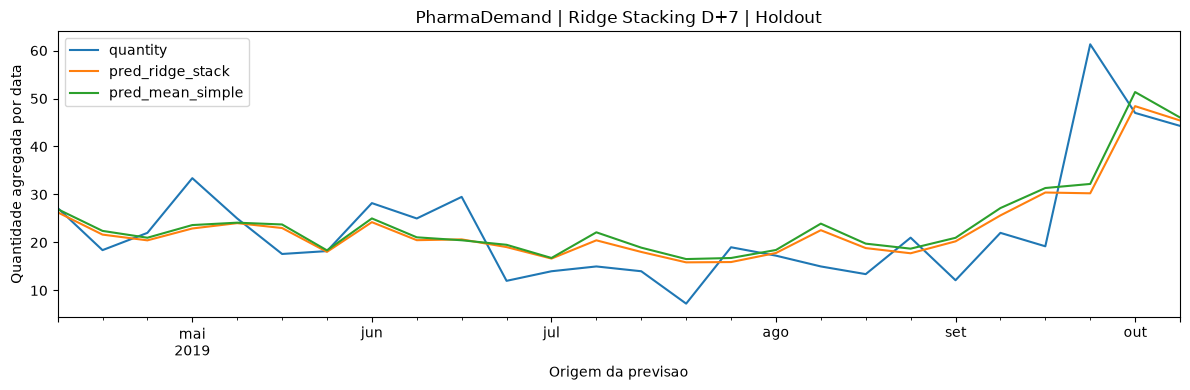

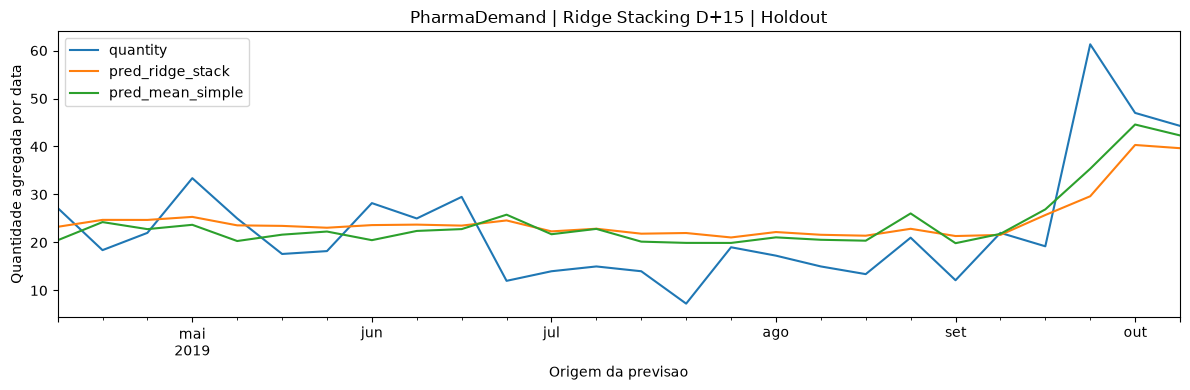

In [18]:
for h in HORIZONS:
    sub = predictions_df.loc[predictions_df["horizon_days"] == h]
    plot_df = sub.groupby("date", as_index=False)[[target_col, "pred_ridge_stack", "pred_mean_simple"]].sum()
    ax = plot_df.plot(x="date", y=[target_col, "pred_ridge_stack", "pred_mean_simple"],
                      figsize=(12, 4), title=f"PharmaDemand | Ridge Stacking D+{h} | Holdout")
    ax.set_ylabel("Quantidade agregada por data")
    ax.set_xlabel("Origem da previsao")
    plt.tight_layout()
    plt.show()

## 9. Métricas por categoria ATC (diagnóstico)

Para portfolio, além do score agregado, acompanhe onde o ensemble melhora e onde piora em comparação com o melhor modelo-base. Não selecione o metamodelo com base no teste; use esse resultado como avaliação final e faça novas escolhas com uma validação anterior ao holdout.

In [24]:
rows = []
for (h, cat), grp in predictions_df.groupby(["horizon_days", "category"]):
    for pred_col in ["pred_lightgbm", "pred_xgboost", "pred_sarimax", "pred_ridge_stack"]: #"pred_autotheta",
        metr = RidgeStackingRegressor.calculate_metrics(grp[target_col], grp[pred_col])
        rows.append({"horizon_days": h, "category": cat, "modelo": pred_col, **metr})
metrics_category = pd.DataFrame(rows)
display(metrics_category.sort_values(["horizon_days", "category", "rmse"]))
metrics_category.to_csv(STACKING_DIR / "ridge_stack_metrics_by_category.csv", index=False)

,horizon_days,category,modelo,mae,rmse,r2,wape_pct,bias
3,7,N02BE,pred_ridge_stack,5.548109,8.143135,0.535542,24.109112,0.252605
1,7,N02BE,pred_xgboost,6.217375,8.316275,0.515581,27.017382,0.847427
0,7,N02BE,pred_lightgbm,6.463400,8.393673,0.506522,28.086473,1.264021
2,7,N02BE,pred_sarimax,6.290388,9.426114,0.377658,27.334656,1.222522
4,15,N02BE,pred_lightgbm,6.587703,8.067571,0.544122,28.626629,-0.021646
5,15,N02BE,pred_xgboost,6.694371,8.247151,0.523601,29.090151,1.458361
7,15,N02BE,pred_ridge_stack,6.881669,9.093521,0.420801,29.904048,1.594120
6,15,N02BE,pred_sarimax,7.063248,9.798891,0.327461,30.693091,2.236111


## 10. Reutilização dos artefatos sem repetir o GridSearch

Ao reiniciar o notebook, é possível usar `load_model()` para previsão direta, **ou** `fit_with_best_params(df_oof_train, params_path=...)` para reajustar o Ridge com os parâmetros previamente salvos (sem repetir o GridSearch). Neste segundo caso, certifique-se de usar novamente **apenas dados OOF**.

```python
h = 15
meta = RidgeStackingRegressor(
    target_col="quantity",
    numeric_features=PRED_COLS,
    categorical_features=["category"],
    model_dir=MODELS_STACKING / "dplus_15",
    date_col="date", gap_days=h,
)
meta.load_model(MODELS_STACKING / "dplus_15" / "ridge_stack_dplus_15.joblib")
predictions = meta.predict(splits[h][1])
# Alternativa de retreino:
# meta.fit_with_best_params(splits[h][0],
#     params_path=MODELS_STACKING / "dplus_15" / "ridge_stack_params_dplus_15.json")
```

### Checklist antes de divulgar métricas no GitHub

1. **Base:** OOF de LightGBM, XGBoost, SARIMAX e AutoTheta produzidas sob os mesmos cortes por origem, categoria e horizonte, com disponibilidade dos rótulos respeitada.
2. **Meta:** nenhuma previsão in-sample, nenhum teste usado para ajuste; Ridge e escalonamento treinados só nos folds permitidos.
3. **Holdout:** dados cronologicamente posteriores, previsões dos quatro modelos-base geradas sem treinar sobre observações futuras.
4. **Comparação:** confrontar Ridge, média simples e cada base no mesmo conjunto; reportar MAE, RMSE, R², WAPE e Bias, inclusive por ATC.
5. **Produção:** na inferência, gerar as quatro previsões-base na mesma ordem/mesmas unidades; só então passar as quatro colunas ao Ridge. A categoria deve estar presente quando o modelo foi treinado com one-hot.

**Dica de arquitetura:** o notebook `05_lightgbm.ipynb` continua treinando o modelo-base. Este `06_ridge_stacking.ipynb` é uma **etapa posterior** e não deve executar os treinos dos quatro modelos-base novamente em todo o dataset para fabricar suas features de meta-treino.

In [20]:
# Comparar os alvos de D+7 e D+15
# para a mesma data e categoria

audit = predictions_df.pivot(
    index=["date", "category"],
    columns="horizon_days",
    values="quantity"
).dropna(subset=[7, 15])

audit["diferenca"] = audit[7] - audit[15]

print("Linhas comparadas:", len(audit))
print(
    "Alvos idênticos:",
    (audit["diferenca"].abs() < 1e-8).sum()
)
print(
    "Divergência máxima:",
    audit["diferenca"].abs().max()
)

display(audit.head(15))

Linhas comparadas: 26
Alvos idênticos: 26
Divergência máxima: 0.0


,horizon_days,7,15,diferenca
date,category,,,
2019-04-16,N02BE,27.20,27.20,0.0
2019-04-23,N02BE,18.40,18.40,0.0
2019-04-30,N02BE,22.00,22.00,0.0
2019-05-07,N02BE,33.40,33.40,0.0
2019-05-14,N02BE,25.00,25.00,0.0
2019-05-21,N02BE,17.60,17.60,0.0
2019-05-28,N02BE,18.20,18.20,0.0
2019-06-04,N02BE,28.20,28.20,0.0
2019-06-11,N02BE,25.00,25.00,0.0


In [21]:
import numpy as np
import pandas as pd

base = pd.read_parquet(
    ROOT / "data/features/anomaly_predictions.parquet"
).copy()

base["date"] = pd.to_datetime(base["date"]).dt.normalize()

comparacao = base.pivot_table(
    index=["date", "category", "split"],
    columns="horizon_days",
    values="quantity",
    aggfunc="first"
).dropna(subset=[7, 15])

comparacao["iguais"] = np.isclose(
    comparacao[7],
    comparacao[15],
    atol=1e-8,
    rtol=0
)

comparacao["diferenca"] = comparacao[7] - comparacao[15]

resumo = comparacao.groupby(level="split").agg(
    total=("iguais", "size"),
    valores_iguais=("iguais", "sum"),
    percentual_iguais=("iguais", "mean"),
    diferenca_media=("diferenca", lambda x: x.abs().mean())
)

resumo["percentual_iguais"] *= 100

display(resumo)

,total,valores_iguais,percentual_iguais,diferenca_media
split,,,,
test,183,183,100.0,0.0
train,1852,1852,100.0,0.0


In [23]:
#"pred_autotheta",
cols = [
    "date",
    "horizon_days",
    "quantity",
    "pred_lightgbm",
    "pred_xgboost",
    "pred_sarimax",  
    "pred_mean_simple",
    "pred_ridge_stack"
]

display(
    predictions_df.loc[
        (predictions_df["category"] == "N02BE") &
        (predictions_df["date"] == "2019-04-16"),
        cols
    ].sort_values("horizon_days").T
)

,0,26
date,2019-04-16 00:00:00,2019-04-16 00:00:00
horizon_days,7,15
quantity,27.2,27.2
pred_lightgbm,26.649825,16.04023
pred_xgboost,27.489803,19.641031
pred_sarimax,26.699127,25.679933
pred_mean_simple,26.946252,20.453731
pred_ridge_stack,26.286477,23.258405
